# H3: is there a shared, signed "which candidate to copy" interface? (Colab, GPT-2 Medium)

This notebook runs the **H3 shared-interface test** from the circuit-reuse blueprint
(Phase 1, step 5). It asks one question: do the IOI inhibition heads and the Colored
Objects content-gatherer heads write **one shared variable** that the mover heads read,
with opposite signs (suppress vs promote)?

The variable is defined to be **token-independent**: the *slot* (order of mention) of the
candidate the movers should copy. That is the only thing names and colours can share, and
it sidesteps the identity shortcut found in the Part 1 / Exp 2 work.

| Block | Question | H3 predicts |
|---|---|---|
| **E0** gate | Does GPT-2 Medium do both tasks, and does the Merullo et al. forced-attention fix reproduce? | IOI ≥ 90%; CO-3 near 49.6% → near 93.7% |
| **E1** writer sign | Is each writer's effect on mover attention a fixed sign (a property of the head, not the task)? | Inhibitors negative, gatherers positive, **in both tasks** |
| **E2** shared code | With token identity held fixed, does the slot code that inhibitors write in IOI point the same way, in mover-query space, as the code gatherers write in CO? | cos > 0, above random-head and permutation nulls |
| **E3** interchange | Does a slot subspace learned on IOI alone move CO answers *and mover attention* as predicted? | Cross-task IIA ≫ random subspaces, ≥ 50% of the CO-trained ceiling; works when applied **only to mover queries** |
| **E4** transplant | Does writing the IOI slot code into CO reproduce the Merullo gain without forcing attention? | ≥ 50% of the forced-attention gain, ≤ 5% new errors |

The decision rule at the end maps these to **H3 supported / H2 only / H3 falsified /
uninformative**. Thresholds are proposals to fix after this pilot, not results.

**Before running**
- Runtime → Change runtime type → **T4 GPU**. GPT-2 Medium is ungated; no token needed.
- Runtime → Run all. Not timed on a GPU yet; my estimate is **40–60 min** on a T4, most of it DAS
  training. `QUICK = True` gives a ~10-minute run with fewer prompts, ranks and seeds.
- `SMOKE = True` swaps in a tiny random model and a toy tokenizer. It only checks that the code runs;
  every number it prints is meaningless.

Everything here is **pilot data**: use it to fix thresholds, ranks and the DAS site before the
confirmatory run, and never reuse these prompts for that run.

TransformerLens 4.0 removed `HookedTransformer`, so the install is pinned to the last 2.x release.
`--no-deps` keeps Colab's own torch / transformers; the second line adds what 2.18 imports.

In [ ]:
%pip install -q --no-deps transformer_lens==2.18.0
%pip install -q einops jaxtyping fancy_einsum better_abc typeguard beartype datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 239.9/239.9 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 2.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformer-lens 2.18.0 requires transformers-stream-generator<0.0.6,>=0.0.5, which is not installed.
transformer-lens 2.18.0 requires beartype<0.15.0,>=0.14.1, but you have beartype 0.22.9 which is incompatible.
transformer-lens 2.18.0 requires huggingface-hub<1.0,>=0.23.2, but you have huggingface-hub 1.33.0 which is incompatible.


## Configuration

In [ ]:
MODEL_NAME = "gpt2-medium"
SMOKE = False            # tiny random model + toy tokenizer, CPU: code-path test only
QUICK = False            # fewer prompts, ranks, seeds and steps

SEED = 0
PREPEND_BOS = False      # Merullo et al. ran without BOS; keep it for comparability with 49.6% / 93.7%
BATCH = 32

# Heads (layer, head) from Merullo, Eickhoff & Pavlick (ICLR 2024), GPT-2 Medium.
# Replace with your own Phase 1 step-1 reproduction lists once you have them.
INHIB     = [(12, 3), (13, 4), (13, 13)]                     # IOI S-inhibition
GATHER    = [(11, 6), (11, 7), (12, 15)]                     # Colored Objects content gatherers (13.3 weaker)
MOVERS    = [(15, 14), (16, 15), (17, 4), (18, 5), (19, 15)] # name / colour movers (14.14 also in CO)
NEG_MOVER = [(19, 1)]
WRITER_POOL_LAYERS = [10, 11, 12, 13]   # random-head nulls are drawn from these layers

# Data
N_IOI_TRAIN, N_IOI_TEST = 600, 200      # DAS pairs; names are split into disjoint train / test pools
N_CO_TRAIN,  N_CO_TEST  = 600, 200      # objects are split too; colours (only 8) are shared
N_GATE     = 400                        # single prompts per task for E0 / E4
N_CONTRAST = 300                        # identity-held contrast pairs for E2

# E3: distributed alignment search
DAS_LAYER    = 14                       # resid_pre 14: after every writer (<= 13), before every mover (>= 15)
SWEEP_LAYERS = [6, 10, 12, 14, 16, 18]  # layer profile at the primary rank, seed 0
DAS_RANKS    = [1, 2, 4]
DAS_SEEDS    = [0, 1, 2]
DAS_STEPS, DAS_LR, DAS_BATCH = 300, 1e-2, 32
N_RAND_SUBSPACES = 100

# E2 / E4
N_RAND_HEADSETS = 1000
N_PERM = 1000
STEER_ALPHAS = [0.5, 1.0, 2.0]

# Pre-registration proposals (fix these after the pilot)
TH = dict(
    ioi_gate=0.90,          # E0: IOI candidate accuracy
    min_writer_mass=0.10,   # E1: a writer must put >= this attention on the candidates to be testable
    min_reliability=0.30,   # E2: split-half cosine needed for the code to count as measured
    rho=0.50,               # E3: cross-task IIA must recover >= this share of the within-CO ceiling
    min_ceiling=0.50,       # E3: below this CO-trained IIA, the test is uninformative
    attn_move=0.70,         # E3: share of pairs whose mover attention moves toward the predicted slot
    transplant_share=0.50,  # E4: share of the Merullo forced-attention gain
    max_new_errors=0.05,    # E4
)
N_BOOT = 1000
OUT_DIR = "h3_interface_results"
SAVE_TO_DRIVE = False

if QUICK:
    N_IOI_TRAIN, N_IOI_TEST, N_CO_TRAIN, N_CO_TEST = 300, 120, 300, 120
    N_GATE, N_CONTRAST = 200, 150
    DAS_RANKS, DAS_SEEDS, DAS_STEPS = [1, 2], [0], 150
    SWEEP_LAYERS, N_RAND_SUBSPACES, N_BOOT = [10, 14, 18], 40, 300
if SMOKE:
    N_IOI_TRAIN, N_IOI_TEST, N_CO_TRAIN, N_CO_TEST = 48, 24, 48, 24
    N_GATE, N_CONTRAST, BATCH = 30, 24, 16
    DAS_RANKS, DAS_SEEDS, DAS_STEPS, DAS_BATCH = [1, 2], [0], 3, 8
    SWEEP_LAYERS, N_RAND_SUBSPACES, N_RAND_HEADSETS, N_PERM, N_BOOT = [10, 14], 5, 50, 50, 50

## Setup: model, tokenizer, hooks
The model is loaded the way Merullo et al. load it (`fold_ln`, `center_writing_weights`,
`center_unembed`), so head indices and numbers are directly comparable. Prompts are
right-padded; with causal attention the final real position is unaffected by padding, and
every hook indexes that position per prompt.

In [ ]:
import os, re, json, math, random, time, itertools
from collections import defaultdict
from functools import partial
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
import transformer_lens, transformers
from importlib.metadata import version as _ver
TL_VERSION = _ver("transformer_lens")
assert int(TL_VERSION.split(".")[0]) < 4, f"TransformerLens {TL_VERSION} has no HookedTransformer; run the install cell (2.18.0)"
from transformer_lens import HookedTransformer, HookedTransformerConfig
print(f"torch {torch.__version__} | transformers {transformers.__version__} | transformer_lens {TL_VERSION}")

torch.set_grad_enabled(False)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)
DEV = "cuda" if torch.cuda.is_available() and not SMOKE else "cpu"


class ToyTokenizer:
    """GPT-2-like word-level tokenizer for SMOKE runs (leading space attaches to the next word)."""
    def __init__(self, vocab_size):
        self.vocab, self.V = {"<|endoftext|>": 0}, vocab_size
        self.eos_token_id = self.bos_token_id = 0

    def __call__(self, text, return_offsets_mapping=True, add_special_tokens=False):
        ids, offs = [], []
        for m in re.finditer(r" ?[A-Za-z]+| ?[^\sA-Za-z]|\n| ", text):
            t = m.group()
            if t not in self.vocab:
                assert len(self.vocab) < self.V, "toy vocab full"
                self.vocab[t] = len(self.vocab)
            ids.append(self.vocab[t]); offs.append((m.start(), m.end()))
        return {"input_ids": ids, "offset_mapping": offs}


if SMOKE:
    cfg = HookedTransformerConfig(n_layers=24, d_model=64, n_heads=16, d_head=4, d_mlp=128, n_ctx=256,
                                  d_vocab=1200, act_fn="gelu_new", normalization_type="LNPre", seed=SEED)
    model = HookedTransformer(cfg).to(DEV)
    tok = ToyTokenizer(cfg.d_vocab)
    LOADED = "SMOKE (random 24x16 model, toy tokenizer)"
else:
    model = HookedTransformer.from_pretrained(MODEL_NAME, center_unembed=True, center_writing_weights=True,
                                              fold_ln=True, device=DEV)
    tok = model.tokenizer
    LOADED = MODEL_NAME
model.eval()
for p in model.parameters():
    p.requires_grad_(False)
NL, NH, D, DH = model.cfg.n_layers, model.cfg.n_heads, model.cfg.d_model, model.cfg.d_head
EPS = model.cfg.eps
PAD_ID = tok.eos_token_id
assert model.cfg.normalization_type == "LNPre", "expected folded LayerNorm (fold_ln=True)"
print(f"{LOADED}: {NL} layers x {NH} heads, d_model {D}, device {DEV}")


def encode(text, bos=PREPEND_BOS):
    enc = tok(text, return_offsets_mapping=True, add_special_tokens=False)
    ids, offs = list(enc["input_ids"]), list(enc["offset_mapping"])
    if bos:
        ids, offs = [tok.bos_token_id] + ids, [(0, 0)] + offs
    return ids, offs


def single_token(word):
    ids, _ = encode(word, bos=False)
    return ids[0] if len(ids) == 1 else None


def lnpre(v):
    v = v - v.mean(-1, keepdim=True)
    return v / (v.pow(2).mean(-1, keepdim=True) + EPS).sqrt()


def head_out(z, l, h):
    """Head (l, h)'s write into the residual stream from its hook_z slice [.., d_head]."""
    return z @ model.W_O[l, h]


# ---- batched forward with per-prompt final-position hooks -------------------------------------
MAXSLOT = 3

def pad(batch):
    T = max(len(q["ids"]) for q in batch)
    toks = torch.full((len(batch), T), PAD_ID, dtype=torch.long)
    M = torch.zeros(len(batch), MAXSLOT, T)        # candidate-slot position masks for attention readouts
    for i, q in enumerate(batch):
        toks[i, :len(q["ids"])] = torch.tensor(q["ids"])
        for k, ps in enumerate(q["cand_pos"]):
            M[i, k, ps] = 1.0
    lasts = torch.tensor([q["last"] for q in batch])
    return toks.to(DEV), lasts.to(DEV), M.to(DEV)


def _grab(x, hook, store, name, ar, lasts, M, keep_grad=False):
    if name.endswith("hook_pattern"):
        rows = x[ar, :, lasts, :]                              # [B, H, Tk]: attention from the final position
        store[name] = torch.einsum("bht,bkt->bhk", rows, M).detach()   # mass on each candidate slot
    else:
        v = x[ar, lasts]
        store[name] = v if keep_grad else v.detach()
    return x


def run_batch(prompts, idx, builders=(), grab=(), grad=False):
    batch = [prompts[i] for i in idx]
    toks, lasts, M = pad(batch)
    ar = torch.arange(len(batch), device=DEV)
    idx_t = torch.tensor(idx, device=DEV)
    store, hs = {}, []
    for b in builders:
        hs += b(idx_t, lasts, ar, batch)
    for name in grab:
        hs.append((name, partial(_grab, store=store, name=name, ar=ar, lasts=lasts, M=M)))
    hs.append(("ln_final.hook_normalized",
               partial(_grab, store=store, name="final", ar=ar, lasts=lasts, M=M, keep_grad=grad)))
    with torch.set_grad_enabled(grad):
        model.run_with_hooks(toks, return_type=None, fwd_hooks=hs)
        logits = store.pop("final") @ model.W_U + model.b_U
    return logits.float(), store


def run(prompts, builders=(), grab=()):
    LG, ST = [], defaultdict(list)
    for s in range(0, len(prompts), BATCH):
        lg, st = run_batch(prompts, list(range(s, min(s + BATCH, len(prompts)))), builders, grab)
        LG.append(lg.cpu())
        for k, v in st.items():
            ST[k].append(v.float().cpu())
    return torch.cat(LG), {k: torch.cat(v) for k, v in ST.items()}


def chunks(xs, n):
    for i in range(0, len(xs), n):
        yield xs[i:i + n]


# ---- interventions (each returns a hook builder) ----------------------------------------------
def hb_resid_swap(L, Q, src):
    """Interchange the subspace span(Q) of resid_pre[L] at the final position with the source's value."""
    def builder(idx, lasts, ar, batch):
        sv = src[idx.cpu()].to(DEV)
        def f(x, hook):
            hb = x[ar, lasts]
            x = x.clone()
            x[ar, lasts] = hb + ((sv - hb) @ Q) @ Q.T
            return x
        return [(f"blocks.{L}.hook_resid_pre", f)]
    return builder


def hb_query_only(heads, delta_fn):
    """Change only the *query* of the given heads at the final position: q = LN(x + delta) W_Q + b_Q.
    Everything else in the model sees the clean residual. delta_fn(idx, layer, x) -> [B, d_model]."""
    layers = sorted({l for l, _ in heads})
    def builder(idx, lasts, ar, batch):
        st, hs = {}, []
        for l in layers:
            hl = [h for L_, h in heads if L_ == l]
            def g(x, hook, l=l):
                st[l] = x[ar, lasts]
                return x
            def fq(q, hook, l=l, hl=hl):
                x = st[l]
                xn = lnpre(x + delta_fn(idx, l, x))
                q = q.clone()
                for h in hl:
                    q[ar, lasts, h] = xn @ model.W_Q[l, h] + model.b_Q[l, h]
                return q
            hs += [(f"blocks.{l}.hook_resid_pre", g), (f"blocks.{l}.attn.hook_q", fq)]
        return hs
    return builder


def hb_force_attention(heads, slots_fn):
    """Merullo-style: force heads' attention from the final position to be uniform over the positions
    of the candidate slots slots_fn(q) returns (e.g. the wrong colours)."""
    def builder(idx, lasts, ar, batch):
        T = max(len(q["ids"]) for q in batch)
        rows = torch.zeros(len(batch), T)
        for i, q in enumerate(batch):
            ps = [p for k in slots_fn(q) for p in q["cand_pos"][k]]
            rows[i, ps] = 1.0 / len(ps)
        rows = rows.to(DEV)
        hs = []
        for l in sorted({l for l, _ in heads}):
            hl = [h for L_, h in heads if L_ == l]
            def f(x, hook, hl=hl):
                x = x.clone()
                for h in hl:
                    x[ar, h, lasts, :] = rows
                return x
            hs.append((f"blocks.{l}.attn.hook_pattern", f))
        return hs
    return builder


def hb_add(L, delta_fn):
    def builder(idx, lasts, ar, batch):
        def f(x, hook):
            x = x.clone()
            x[ar, lasts] = x[ar, lasts] + delta_fn(idx, x[ar, lasts])
            return x
        return [(f"blocks.{L}.hook_resid_pre", f)]
    return builder


def boot_ci(x, n=None, seed=SEED):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    if len(x) == 0:
        return (np.nan, np.nan)
    r = np.random.default_rng(seed)
    m = [x[r.integers(0, len(x), len(x))].mean() for _ in range(n or N_BOOT)]
    return tuple(float(v) for v in np.percentile(m, [2.5, 97.5]))


MOVER_PAT = sorted({f"blocks.{l}.attn.hook_pattern" for l, _ in MOVERS})

def mover_mass(st):
    """Mean attention mass over the mover heads from the final position, per candidate slot: [N, 3]."""
    return torch.stack([st[f"blocks.{l}.attn.hook_pattern"][:, h] for l, h in MOVERS]).mean(0)

torch 2.11.0+cu130 | transformers 5.18.0 | transformer_lens 2.18.0


config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loaded pretrained model gpt2-medium into HookedTransformer
gpt2-medium: 24 layers x 16 heads, d_model 1024, device cuda


## Tasks
**IOI** uses the Wang et al. BABA/ABBA templates. The candidates are the two names in order of first
mention; the *answer slot* is the slot of the indirect object.

**Colored Objects (CO)** uses the Merullo et al. one-shot format with the 8 simple colours and
17 objects. The candidates are the test example's colours in list order; the answer slot is the
queried object's position. **CO-2** (two objects) matches IOI's two slots and is the main cross-task
target; **CO-3** is the Merullo setting, used for E0, E4 and a slot-generalisation check in E3.

Two deviations from Merullo, both so that positions are unambiguous: the demo uses colours and
objects disjoint from the test example's, and objects are split into train / test pools.

**Answer tokens.** Names are scored as " Name"; colours as the capitalised " Colour" the format asks
for. Attention readouts use the in-context mention positions (lower-case colour words).

In [ ]:
NAMES = """Aaron Adam Alan Alex Alice Amy Anderson Andre Andrew Andy Anna Anthony Arthur Austin Blake Brandon
Brian Carter Charles Charlie Christian Christopher Clark Cole Collins Connor Crystal Daniel David Dean Edward
Elizabeth Emily Eric Eva Ford Frank George Georgia Graham Grant Henry Ian Jack Jacob Jake James Jamie Jane
Jason Jay Jennifer Jeremy Jessica John Jonathan Jordan Joseph Joshua Justin Kate Kelly Kevin Kyle Laura Leon
Lewis Lisa Louis Luke Madison Marco Marcus Maria Mark Martin Mary Matthew Max Michael Michelle Morgan Patrick
Paul Peter Rachel Richard Robert Roman Rose Ruby Russell Ryan Sarah Scott Sean Simon Stephen Steven Taylor
Thomas Tyler Victoria Warren William""".split()
PLACES = ["store", "garden", "restaurant", "school", "hospital", "office", "house", "station"]
IOI_OBJECTS = ["ring", "kiss", "bone", "basketball", "computer", "necklace", "drink", "snack"]
IOI_TEMPLATES = [
    "Then, {A} and {B} went to the {PLACE}. {S} gave a {OBJECT} to",
    "Then, {A} and {B} had a lot of fun at the {PLACE}. {S} gave a {OBJECT} to",
    "Then, {A} and {B} were working at the {PLACE}. {S} decided to give a {OBJECT} to",
    "Then, {A} and {B} were thinking about going to the {PLACE}. {S} wanted to give a {OBJECT} to",
    "Then, {A} and {B} had a long argument, and afterwards {S} said to",
    "After {A} and {B} went to the {PLACE}, {S} gave a {OBJECT} to",
    "When {A} and {B} got a {OBJECT} at the {PLACE}, {S} decided to give it to",
    "While {A} and {B} were working at the {PLACE}, {S} gave a {OBJECT} to",
    "While {A} and {B} were commuting to the {PLACE}, {S} gave a {OBJECT} to",
    "After the lunch, {A} and {B} went to the {PLACE}. {S} gave a {OBJECT} to",
    "Afterwards, {A} and {B} went to the {PLACE}. {S} gave a {OBJECT} to",
    "Friends {A} and {B} found a {OBJECT} at the {PLACE}. {S} gave it to",
]
CO_OBJECTS = ["pencil", "notebook", "pen", "cup", "plate", "jug", "mug", "puzzle", "textbook", "leash",
              "necklace", "bracelet", "bottle", "ball", "envelope", "lighter", "bowl"]
CO_COLORS = ["red", "orange", "yellow", "green", "blue", "purple", "brown", "black"]
SURFACES, SUBJ_STARTS = ["table", "desk", "floor"], ["there is", "you see", "I see"]


def build(pieces):
    """pieces: str or (str, tag). Returns text and {tag: (start, end)} character spans."""
    text, spans = "", {}
    for p in pieces:
        if isinstance(p, tuple):
            spans[p[1]] = (len(text), len(text) + len(p[0]))
            text += p[0]
        else:
            text += p
    return text, spans


def make_ioi(first, second, s_slot, tpl, place, obj):
    """Names in mention order (first, second); the subject S sits in s_slot; the answer is the other slot."""
    names = [first, second]
    pieces = []
    for part in re.split(r"(\{A\}|\{B\}|\{S\}|\{PLACE\}|\{OBJECT\})", IOI_TEMPLATES[tpl]):
        if part == "{A}":   pieces.append((first, "c0"))
        elif part == "{B}": pieces.append((second, "c1"))
        elif part == "{S}": pieces.append((names[s_slot], "s2"))
        elif part == "{PLACE}": pieces.append(place)
        elif part == "{OBJECT}": pieces.append(obj)
        elif part: pieces.append(part)
    text, spans = build(pieces)
    return dict(task="ioi", n=2, text=text, spans=spans, tag_slot={"c0": 0, "c1": 1, "s2": s_slot},
                cands=names, out_words=names, ans_slot=1 - s_slot,
                meta=dict(tpl=tpl, place=place, obj=obj))


def co_example(surface, ss, colors, objects, q_idx, tag=False):
    pieces = [f"Q: On the {surface}, {ss} "]
    n = len(colors)
    for i, (c, o) in enumerate(zip(colors, objects)):
        art = "an" if c[0] in "aeiou" else "a"
        pieces += [f"{art} ", (c, f"c{i}") if tag else c, f" {o}"]
        if i < n - 1:
            pieces.append(", and " if (n > 2 and i == n - 2) else (" and " if n == 2 else ", "))
    pieces.append(f". What color is the {objects[q_idx]}?\nA:")
    return pieces


def make_co(colors, objects, q_idx, demo, surface, ss):
    """demo = (surface, ss, colors, objects, q_idx) for the one-shot example."""
    dpieces = co_example(*demo)
    dtext = build(dpieces)[0] + " " + demo[2][demo[4]].capitalize() + "\n"
    text, spans = build([dtext] + co_example(surface, ss, colors, objects, q_idx, tag=True))
    n = len(colors)
    return dict(task=f"co{n}", n=n, text=text, spans=spans, tag_slot={f"c{i}": i for i in range(n)},
                cands=list(colors), out_words=[c.capitalize() for c in colors], ans_slot=q_idx,
                meta=dict(objects=list(objects), surface=surface, ss=ss, demo=demo))


def overlap(offs, s, e):
    return [k for k, (a, b) in enumerate(offs) if b > a and a < e and b > s]


def prepare(q):
    ids, offs = encode(q["text"])
    out_ids = []
    for w in q["out_words"]:
        t = single_token(" " + w)
        if t is None:
            return None, f"output ' {w}' is not one token"
        out_ids.append(t)
    if len(set(out_ids)) != len(out_ids):
        return None, "duplicate candidates"
    cand_pos = [[] for _ in range(q["n"])]
    for tag, (s, e) in q["spans"].items():
        ov = overlap(offs, s, e)
        if len(ov) != 1:
            return None, f"'{q['text'][s:e]}' is not one token in context"
        cand_pos[q["tag_slot"][tag]].append(ov[0])
    return dict(q, ids=ids, last=len(ids) - 1, out_ids=out_ids, ans_id=out_ids[q["ans_slot"]],
                cand_pos=cand_pos), None


DROPPED = defaultdict(int)

def keep(q):
    p, err = prepare(q)
    if err:
        DROPPED[(q["task"], err.split("'")[0] + "...")] += 1
    return p


# Single-token filters and disjoint pools
NAMES_OK = [n for n in NAMES if single_token(" " + n) is not None]
rng0 = random.Random(SEED)
_names = NAMES_OK[:]; rng0.shuffle(_names)
NAME_POOL = {"train": _names[:int(0.7 * len(_names))], "test": _names[int(0.7 * len(_names)):]}
_objs = CO_OBJECTS[:]; rng0.shuffle(_objs)
OBJ_POOL = {"train": _objs[:11], "test": _objs[11:]}
print(f"single-token names: {len(NAMES_OK)}/{len(NAMES)} -> train {len(NAME_POOL['train'])} / test {len(NAME_POOL['test'])}")
print("CO colours that are one token as ' Colour':", [c for c in CO_COLORS if single_token(' ' + c.capitalize())])


def rand_ioi(rng, split, ans_slot=None, avoid=()):
    while True:
        a, b = rng.sample([n for n in NAME_POOL[split] if n not in avoid], 2)
        s = rng.choice([0, 1]) if ans_slot is None else 1 - ans_slot
        q = keep(make_ioi(a, b, s, rng.randrange(len(IOI_TEMPLATES)), rng.choice(PLACES), rng.choice(IOI_OBJECTS)))
        if q: return q


def rand_co(rng, split, n, ans_slot=None, avoid_colors=()):
    while True:
        colors = rng.sample([c for c in CO_COLORS if c not in avoid_colors], n)
        objects = rng.sample(OBJ_POOL[split], n)
        rest_c = [c for c in CO_COLORS if c not in colors]
        rest_o = [o for o in CO_OBJECTS if o not in objects]
        demo = (rng.choice(SURFACES), rng.choice(SUBJ_STARTS), rng.sample(rest_c, n), rng.sample(rest_o, n),
                rng.randrange(n))
        k = rng.randrange(n) if ans_slot is None else ans_slot
        q = keep(make_co(colors, objects, k, demo, rng.choice(SURFACES), rng.choice(SUBJ_STARTS)))
        if q: return q


def make_pairs(task, N, split, rng, n=2):
    """Interchange pairs: base and source share no candidates and differ in answer slot.
    Prediction after swapping the slot variable: the base outputs ITS OWN candidate at the SOURCE's slot."""
    pairs = []
    for _ in range(N):
        if task == "ioi":
            b = rand_ioi(rng, split)
            s = rand_ioi(rng, split, ans_slot=1 - b["ans_slot"], avoid=b["cands"])
        else:
            b = rand_co(rng, split, n)
            s = rand_co(rng, split, n, ans_slot=rng.choice([k for k in range(n) if k != b["ans_slot"]]),
                        avoid_colors=b["cands"])
        pairs.append(dict(base=b, src=s, tgt_slot=s["ans_slot"], tgt_id=b["out_ids"][s["ans_slot"]]))
    return pairs


rng = random.Random(SEED + 1)
PAIRS = {
    "ioi_train": make_pairs("ioi", N_IOI_TRAIN, "train", rng),
    "ioi_test":  make_pairs("ioi", N_IOI_TEST, "test", rng),
    "co2_train": make_pairs("co", N_CO_TRAIN, "train", rng, n=2),
    "co2_test":  make_pairs("co", N_CO_TEST, "test", rng, n=2),
    "co3_test":  make_pairs("co", N_CO_TEST, "test", rng, n=3),
}
SINGLE = {
    "ioi": [rand_ioi(rng, "test") for _ in range(N_GATE)],
    "co2": [rand_co(rng, "test", 2) for _ in range(N_GATE)],
    "co3": [rand_co(rng, "test", 3) for _ in range(N_GATE)],
}
print({k: len(v) for k, v in PAIRS.items()}, {k: len(v) for k, v in SINGLE.items()})
if DROPPED:
    print("dropped while sampling:", dict(DROPPED))
for k in ["ioi", "co3"]:
    q = SINGLE[k][0]
    print(f"\n[{k}] ...{q['text'][-150:]!r}\n  candidates {q['cands']} -> answer slot {q['ans_slot']} "
          f"({q['out_words'][q['ans_slot']]!r}), mention positions {q['cand_pos']}")

single-token names: 105/105 -> train 73 / test 32
CO colours that are one token as ' Colour': ['red', 'orange', 'yellow', 'green', 'blue', 'purple', 'brown', 'black']
{'ioi_train': 600, 'ioi_test': 200, 'co2_train': 600, 'co2_test': 200, 'co3_test': 200} {'ioi': 400, 'co2': 400, 'co3': 400}

[ioi] ...'While Leon and Louis were working at the house, Leon gave a basketball to'
  candidates ['Leon', 'Louis'] -> answer slot 1 ('Louis'), mention positions [[1, 10], [3]]

[co3] ...'blue necklace. What color is the mug?\nA: Purple\nQ: On the floor, you see a brown textbook, a green cup, and an orange bowl. What color is the bowl?\nA:'
  candidates ['brown', 'green', 'orange'] -> answer slot 2 ('Orange'), mention positions [[41], [45], [50]]


## E0. Behavioural gate and Merullo reproduction
Accuracy is top-1 among the candidate answers (both names; the test example's colours), plus
full-vocabulary top-1 for reference. The forced-attention arm makes the inhibition heads and the
negative mover attend uniformly to the **wrong** colours from the final position, as in Merullo et al.
Their numbers on CO-3: 49.6% → 81.5% (inhibitors only), 78.1% (19.1 only), 93.7% (both).
Exact reproduction is not expected (different prompt sample, disjoint demo colours); a gain of
roughly that size is.

In [ ]:
def score(prompts, LG):
    cand = np.array([int(int(lg[q["out_ids"]].argmax()) == q["ans_slot"]) for q, lg in zip(prompts, LG)])
    full = np.array([int(lg.argmax().item() == q["ans_id"]) for q, lg in zip(prompts, LG)])
    margin = np.array([(lg[q["ans_id"]] - max(lg[i] for i in q["out_ids"] if i != q["ans_id"])).item()
                       for q, lg in zip(prompts, LG)])
    return cand, full, margin


wrong_slots = lambda q: [k for k in range(q["n"]) if k != q["ans_slot"]]
E0, CLEAN = {}, {}
t0 = time.time()
for task, P in SINGLE.items():
    LG, st = run(P, grab=MOVER_PAT)
    cand, full, margin = score(P, LG)
    CLEAN[task] = dict(cand=cand, mass=mover_mass(st),
                       per_mover={(l, h): st[f"blocks.{l}.attn.hook_pattern"][:, h] for l, h in MOVERS})
    by_slot = {k: float(cand[[q["ans_slot"] == k for q in P]].mean()) for k in range(P[0]["n"])}
    E0[task] = dict(acc=float(cand.mean()), ci=boot_ci(cand), acc_full=float(full.mean()),
                    margin=float(margin.mean()), acc_by_answer_slot=by_slot,
                    chance=1 / P[0]["n"])
for name, heads in [("inhib+neg", INHIB + NEG_MOVER), ("inhib", INHIB), ("neg", NEG_MOVER)]:
    LG, _ = run(SINGLE["co3"], builders=[hb_force_attention(heads, wrong_slots)])
    cand, _, _ = score(SINGLE["co3"], LG)
    E0[f"co3_forced_{name}"] = dict(acc=float(cand.mean()), ci=boot_ci(cand))
    if name == "inhib+neg":
        CLEAN["co3_forced"] = cand
print(f"E0 done in {time.time() - t0:.0f}s\n")
for k, v in E0.items():
    extra = f"  full-vocab {v['acc_full']:.2f}  margin {v['margin']:+.2f}  by answer slot {v['acc_by_answer_slot']}" if "acc_full" in v else ""
    print(f"{k:22s} acc {v['acc']:.3f} [{v['ci'][0]:.3f}, {v['ci'][1]:.3f}]{extra}")
GATE_OK = E0["ioi"]["acc"] >= TH["ioi_gate"]
MERULLO_GAIN = E0["co3_forced_inhib+neg"]["acc"] - E0["co3"]["acc"]
print(f"\nIOI gate ({TH['ioi_gate']:.0%}): {'PASS' if GATE_OK else 'FAIL'};  "
      f"CO-3 forced-attention gain {MERULLO_GAIN:+.3f} (Merullo: +0.441)")
print("Mover attention from the final position (mean over movers), clean:")
for task in SINGLE:
    m = CLEAN[task]["mass"]; P = SINGLE[task]
    on_ans = float(np.mean([m[i, q["ans_slot"]].item() for i, q in enumerate(P)]))
    on_other = float(np.mean([m[i, wrong_slots(q)].sum().item() for i, q in enumerate(P)]))
    print(f"  {task}: on answer {on_ans:.3f}, on other candidates {on_other:.3f}")

E0 done in 28s

ioi                    acc 0.995 [0.988, 1.000]  full-vocab 0.90  margin +3.46  by answer slot {0: 0.9900990099009901, 1: 1.0}
co2                    acc 0.748 [0.705, 0.788]  full-vocab 0.75  margin +0.83  by answer slot {0: 0.8402061855670103, 1: 0.6601941747572816}
co3                    acc 0.560 [0.512, 0.608]  full-vocab 0.56  margin +0.16  by answer slot {0: 0.7535211267605634, 1: 0.45, 2: 0.4576271186440678}
co3_forced_inhib+neg   acc 0.958 [0.938, 0.975]
co3_forced_inhib       acc 0.838 [0.797, 0.873]
co3_forced_neg         acc 0.838 [0.800, 0.873]

IOI gate (90%): PASS;  CO-3 forced-attention gain +0.397 (Merullo: +0.441)
Mover attention from the final position (mean over movers), clean:
  ioi: on answer 0.431, on other candidates 0.089
  co2: on answer 0.392, on other candidates 0.267
  co3: on answer 0.290, on other candidates 0.380


## E1. Is each writer's sign a property of the head?
For each writer head *w* and task, find the candidate *w* attends to most from the final position
(c\*). Then path-patch: replace *w*'s output by its task mean **in the mover heads' queries only**
and measure how mover attention to c\* changes. The writer's signed effect is minus that change:
negative means *w* pushes movers away from what it reads (suppression), positive means toward it.

H3 predicts **inhibitors < 0 and gatherers > 0 in both tasks**. Merullo's intervention already
assumes this for inhibitors in CO (pointing them at wrong colours suppresses those colours), but
never measured it. A writer that puts less than `min_writer_mass` attention on the candidates in a
task is marked untestable there.

In [ ]:
WRITERS = INHIB + GATHER
Z_NAMES = sorted({f"blocks.{l}.attn.hook_z" for l in WRITER_POOL_LAYERS + [l for l, _ in WRITERS]})
W_PAT = sorted({f"blocks.{l}.attn.hook_pattern" for l, _ in WRITERS})


def writer_outputs(P):
    """Final-position output of every head in the writer pool layers: {(l, h): [N, d_model]}, plus writer patterns."""
    _, st = run(P, grab=Z_NAMES + W_PAT)
    outs = {(l, h): head_out(st[f"blocks.{l}.attn.hook_z"][:, h].to(DEV), l, h).cpu()
            for l in sorted({int(n.split('.')[1]) for n in Z_NAMES}) for h in range(NH)}
    return outs, st


E1 = {}
t0 = time.time()
for task in ["ioi", "co3"]:
    P = SINGLE[task]
    outs, st = writer_outputs(P)
    ar = torch.arange(len(P))
    ans = torch.tensor([q["ans_slot"] for q in P])
    for w in WRITERS:
        wl, wh = w
        wmass = st[f"blocks.{wl}.attn.hook_pattern"][:, wh]              # [N, 3] writer attention per slot
        cstar = wmass[:, :P[0]["n"]].argmax(-1)                          # the candidate this writer reads
        o, obar = outs[w].to(DEV), outs[w].mean(0).to(DEV)
        later = [m for m in MOVERS if m[0] > wl]                         # all movers sit above all writers
        delta = lambda idx, l, x, o=o, obar=obar: (obar - o[idx])
        _, stp = run(P, builders=[hb_query_only(later, delta)], grab=MOVER_PAT)
        patched_m = torch.stack([stp[f"blocks.{l}.attn.hook_pattern"][:, h] for l, h in later]).mean(0)
        clean_m = torch.stack([CLEAN[task]["per_mover"][m] for m in later]).mean(0)
        effect = -(patched_m[ar, cstar] - clean_m[ar, cstar]).numpy()   # writer present minus mean-ablated
        E1[(task, w)] = dict(effect=effect, mean=float(effect.mean()), ci=boot_ci(effect),
                             mass_on_cands=float(wmass[:, :P[0]["n"]].sum(-1).mean()),
                             cstar_is_answer=float((cstar == ans).float().mean()),
                             role="inhib" if w in INHIB else "gather")
print(f"E1 done in {time.time() - t0:.0f}s\n")

E1_GROUP = {}
print(f"{'task':5s} {'writer':8s} {'role':7s} {'effect on movers->c*':>22s} {'95% CI':>17s} {'mass on cands':>14s} {'c* = answer':>12s}")
for task in ["ioi", "co3"]:
    for w in WRITERS:
        r = E1[(task, w)]
        print(f"{task:5s} {w[0]:>2d}.{w[1]:<5d} {r['role']:7s} {r['mean']:+22.4f} [{r['ci'][0]:+.4f},{r['ci'][1]:+.4f}] "
              f"{r['mass_on_cands']:14.2f} {r['cstar_is_answer']:12.2f}")
    for role, heads, want in [("inhib", INHIB, -1), ("gather", GATHER, +1)]:
        eff = np.mean([E1[(task, w)]["effect"] for w in heads], 0)
        mass = float(np.mean([E1[(task, w)]["mass_on_cands"] for w in heads]))
        lo, hi = boot_ci(eff)
        testable = mass >= TH["min_writer_mass"]
        ok = (hi < 0) if want < 0 else (lo > 0)
        E1_GROUP[(task, role)] = dict(mean=float(eff.mean()), ci=(lo, hi), mass=mass, testable=testable,
                                      predicted_sign=want, passes=bool(ok) if testable else None)
print("\nGroup level (H3 predicts inhib < 0 and gather > 0 in BOTH tasks):")
for (task, role), r in E1_GROUP.items():
    v = "untestable (writer barely reads the candidates)" if not r["testable"] else ("as predicted" if r["passes"] else "NOT as predicted")
    print(f"  {task:4s} {role:7s} {r['mean']:+.4f} [{r['ci'][0]:+.4f}, {r['ci'][1]:+.4f}]  -> {v}")
tested = [r["passes"] for r in E1_GROUP.values() if r["testable"]]
E1_PASS = bool(tested) and all(tested) and E1_GROUP[("ioi", "inhib")]["testable"] and E1_GROUP[("co3", "gather")]["testable"]

E1 done in 50s

task  writer   role      effect on movers->c*            95% CI  mass on cands  c* = answer
ioi   12.3     inhib                  -0.1482 [-0.1541,-0.1428]           0.66         0.00
ioi   13.4     inhib                  -0.0175 [-0.0188,-0.0162]           0.28         0.00
ioi   13.13    inhib                  -0.0146 [-0.0154,-0.0137]           0.31         0.00
ioi   11.6     gather                 +0.0012 [+0.0009,+0.0014]           0.21         0.00
ioi   11.7     gather                 +0.0009 [+0.0007,+0.0012]           0.08         0.00
ioi   12.15    gather                 +0.0019 [+0.0012,+0.0025]           0.03         0.04
co3   12.3     inhib                  -0.0061 [-0.0082,-0.0038]           0.25         0.46
co3   13.4     inhib                  -0.0034 [-0.0038,-0.0030]           0.15         0.56
co3   13.13    inhib                  -0.0001 [-0.0002,+0.0000]           0.01         0.39
co3   11.6     gather                 -0.0012 [-0.0038,+0.0014] 

## E2. Do the two selection signals write the same slot code into mover-query space?
**Identity-held contrasts.** Each pair keeps every token the same and changes only the answer's slot:
IOI "A and B … B gave … to" vs "B and A … B gave … to" (same names, same answer); CO the same objects
and question with two items swapped. The difference between the pair's writer outputs is therefore
pure slot information, with no name or colour identity in it.

**Mover-query space.** A writer output *v* is mapped to what the movers' queries read from it:
Φ(v) = concat over movers of (v − mean v) / scale · W_Q, where scale is the mover layer's LayerNorm
scale on that prompt. The slot code of a head group is d = mean over pairs of Φ(slot-1 prompt) −
Φ(slot-2 prompt), indexed by the **answer** slot in both tasks.

Under H3 the IOI inhibitors write −e(S's slot) and the CO gatherers write +e(answer's slot), so both
d's point the same way: **cos(d_inhib^IOI, d_gather^CO) > 0**. Two nulls: random size-matched head sets
from layers 10–13 (independent sets per task), and a label permutation (flip each pair's sign).
Split-half cosine within a task is the reliability ceiling; below `min_reliability` the code is not
measured well enough to compare.

In [ ]:
def contrast_pairs(task, N, rng):
    out = []
    while len(out) < N:
        if task == "ioi":
            a, b = rng.sample(NAME_POOL["test"], 2)
            tpl, place, obj = rng.randrange(len(IOI_TEMPLATES)), rng.choice(PLACES), rng.choice(IOI_OBJECTS)
            p0 = keep(make_ioi(a, b, 1, tpl, place, obj))   # answer a in slot 0
            p1 = keep(make_ioi(b, a, 0, tpl, place, obj))   # answer a in slot 1, same tokens
        else:
            q = rand_co(rng, "test", 2, ans_slot=0)
            m = q["meta"]
            p0 = q
            p1 = keep(make_co(q["cands"][::-1], m["objects"][::-1], 1, m["demo"], m["surface"], m["ss"]))
        if p0 and p1:
            out.append((p0, p1))
    return out


MOVER_L = sorted({l for l, _ in MOVERS})
RESID_MOVER = [f"blocks.{l}.hook_resid_pre" for l in MOVER_L]
POOL = [(l, h) for l in WRITER_POOL_LAYERS for h in range(NH)]
NULL_POOL = [w for w in POOL if w not in INHIB + GATHER]


def phi_all(P):
    """Phi(head output) for every head in the writer pool: {(l, h): [N, n_movers * d_head]}."""
    outs, _ = writer_outputs(P)
    _, st = run(P, grab=RESID_MOVER)
    scale = {l: (st[f"blocks.{l}.hook_resid_pre"] - st[f"blocks.{l}.hook_resid_pre"].mean(-1, keepdim=True))
                 .pow(2).mean(-1, keepdim=True).add(EPS).sqrt() for l in MOVER_L}
    WQ = {m: model.W_Q[m[0], m[1]].cpu() for m in MOVERS}
    res = {}
    for w in POOL:
        v = outs[w] - outs[w].mean(-1, keepdim=True)
        res[w] = torch.cat([(v / scale[l]) @ WQ[(l, h)] for l, h in MOVERS], -1)
    return res


def cos(a, b):
    return float(F.cosine_similarity(a.flatten(), b.flatten(), dim=0))


rng = random.Random(SEED + 2)
E2, DIFF = {}, {}
t0 = time.time()
for task in ["ioi", "co2"]:
    CP = contrast_pairs(task, N_CONTRAST, rng)
    ph0, ph1 = phi_all([p[0] for p in CP]), phi_all([p[1] for p in CP])
    DIFF[task] = {w: ph0[w] - ph1[w] for w in POOL}          # [P, dims] per-pair slot contrast (slot0 - slot1)
group_diff = lambda task, heads: sum(DIFF[task][w] for w in heads)

d_ioi, d_co = group_diff("ioi", INHIB), group_diff("co2", GATHER)
E2["cos_cross"] = cos(d_ioi.mean(0), d_co.mean(0))
E2["cos_inhib_both_tasks"] = cos(group_diff("ioi", INHIB).mean(0), group_diff("co2", INHIB).mean(0))
E2["cos_gather_both_tasks"] = cos(group_diff("ioi", GATHER).mean(0), group_diff("co2", GATHER).mean(0))

def split_half(Dm, r):
    idx = r.permutation(len(Dm)); h = len(Dm) // 2
    return cos(Dm[idx[:h]].mean(0), Dm[idx[h:]].mean(0))
r = np.random.default_rng(SEED)
E2["reliability_ioi_inhib"] = float(np.mean([split_half(d_ioi, r) for _ in range(50)]))
E2["reliability_co_gather"] = float(np.mean([split_half(d_co, r) for _ in range(50)]))
E2["signal_ioi_inhib"] = float(d_ioi.mean(0).norm() / d_ioi.norm(dim=-1).mean())   # mean code vs per-pair spread
E2["signal_co_gather"] = float(d_co.mean(0).norm() / d_co.norm(dim=-1).mean())

# Null A: random head sets (independent per task, size-matched)
null_heads = []
for _ in range(N_RAND_HEADSETS):
    a, b = random.sample(NULL_POOL, len(INHIB)), random.sample(NULL_POOL, len(GATHER))
    null_heads.append(cos(group_diff("ioi", a).mean(0), group_diff("co2", b).mean(0)))
# Null B: label permutation (random sign per pair)
null_perm = []
for _ in range(N_PERM):
    s1 = torch.tensor(r.choice([-1.0, 1.0], len(d_ioi)))[:, None]
    s2 = torch.tensor(r.choice([-1.0, 1.0], len(d_co)))[:, None]
    null_perm.append(cos((d_ioi * s1).mean(0), (d_co * s2).mean(0)))
E2["null_heads_p95"], E2["null_perm_p95"] = float(np.percentile(null_heads, 95)), float(np.percentile(null_perm, 95))
E2["pct_vs_null_heads"] = float((np.array(null_heads) < E2["cos_cross"]).mean())

# Subspace overlap of the per-pair contrasts (top-3 principal directions), vs random heads
def top_dirs(Dm, k=3):
    return torch.linalg.svd(Dm, full_matrices=False)[2][:k]
def overlap_k(A, B):
    return float((top_dirs(A) @ top_dirs(B).T).pow(2).sum() / 3)
E2["subspace_overlap"] = overlap_k(d_ioi, d_co)
null_ov = [overlap_k(group_diff("ioi", random.sample(NULL_POOL, 3)), group_diff("co2", random.sample(NULL_POOL, 3)))
           for _ in range(min(200, N_RAND_HEADSETS))]
E2["null_overlap_p95"] = float(np.percentile(null_ov, 95))
E2["null_heads"], E2["null_perm"] = null_heads, null_perm

rel_ok = min(E2["reliability_ioi_inhib"], E2["reliability_co_gather"]) >= TH["min_reliability"]
E2_PASS = rel_ok and E2["cos_cross"] > max(E2["null_heads_p95"], E2["null_perm_p95"])
E2_INFORMATIVE = rel_ok
print(f"E2 done in {time.time() - t0:.0f}s\n")
print(f"cos(d_inhib^IOI, d_gather^CO)  = {E2['cos_cross']:+.3f}   "
      f"null 95th pct: random heads {E2['null_heads_p95']:+.3f}, permutation {E2['null_perm_p95']:+.3f}  "
      f"(percentile vs random heads {E2['pct_vs_null_heads']:.2f})")
print(f"split-half reliability: IOI inhib {E2['reliability_ioi_inhib']:+.2f}, CO gather {E2['reliability_co_gather']:+.2f}  "
      f"(need >= {TH['min_reliability']})")
print(f"signal ratio |mean d| / mean |d_pair|: IOI {E2['signal_ioi_inhib']:.2f}, CO {E2['signal_co_gather']:.2f}")
print(f"top-3 subspace overlap {E2['subspace_overlap']:.3f} vs random-head 95th pct {E2['null_overlap_p95']:.3f}")
print(f"same heads, both tasks: inhib {E2['cos_inhib_both_tasks']:+.3f}, gather {E2['cos_gather_both_tasks']:+.3f}")
print("->", "uninformative (code not reliably measured)" if not rel_ok else ("passes" if E2_PASS else "FAILS (H3 falsifier: codes not aligned)"))

E2 done in 27s

cos(d_inhib^IOI, d_gather^CO)  = +0.551   null 95th pct: random heads +0.357, permutation +0.595  (percentile vs random heads 0.99)
split-half reliability: IOI inhib +1.00, CO gather +1.00  (need >= 0.3)
signal ratio |mean d| / mean |d_pair|: IOI 0.99, CO 0.99
top-3 subspace overlap 0.183 vs random-head 95th pct 0.206
same heads, both tasks: inhib -0.955, gather -0.784
-> FAILS (H3 falsifier: codes not aligned)


## E3. Does an IOI-trained slot subspace move Colored Objects answers and mover attention?
**DAS.** A rank-*r* subspace Q of resid_pre[`DAS_LAYER`] at the final position is trained **on IOI pairs
only**: base and source share no names and have opposite answer slots, and the intervention
h ← h + QQᵀ(h_src − h) should make the base output *its own* name at the *source's* slot. Q is then
frozen and applied to CO pairs (different colours and objects, different answer slot).

**Outcome per pair** (full-vocab top-1): the predicted token (base candidate at source slot), the base's
original answer (no effect), the source's answer token (identity leak, the Exp 1 failure mode), or other.
IIA is top-1 among the base candidates.

**Comparisons.** Within-CO ceiling: a subspace trained on CO-2 itself (this, not a full-rank swap, is
the denominator of ρ; a full swap also carries identity). Full-rank swap, `N_RAND_SUBSPACES` random
subspaces, a shuffled-slot DAS, no intervention, the reverse direction (CO → IOI) and a layer sweep.

**Mover-query-only mode** is the H3-specific test: the same Q swap is applied *only to the queries of
the mover heads* (each at its own layer); the rest of the network sees the clean residual. If IIA and
the attention shift survive this, the variable is read by the movers' queries, as H3 claims.

**Primary rank** is chosen on IOI held-out pairs alone (smallest rank within 0.05 of the best), so the
CO numbers never feed back into the choice.

In [ ]:
def cache_src(pairs, layers):
    _, st = run([p["src"] for p in pairs], grab=[f"blocks.{l}.hook_resid_pre" for l in layers])
    return {l: st[f"blocks.{l}.hook_resid_pre"] for l in layers}


SRC = {k: cache_src(v, sorted(set(SWEEP_LAYERS + [DAS_LAYER] + MOVER_L))) for k, v in PAIRS.items()}
BASE_CLEAN = {}
for k, v in PAIRS.items():
    LG, st = run([p["base"] for p in v], grab=MOVER_PAT)
    BASE_CLEAN[k] = dict(LG=LG, mass=mover_mass(st))


def train_das(key, L, rank, seed, shuffle=False):
    pairs, src = PAIRS[key], SRC[key][L]
    bases = [p["base"] for p in pairs]
    tgt = [p["tgt_id"] for p in pairs]
    if shuffle:                      # shuffled-slot control: random slot labels, same base tokens
        rs = random.Random(seed + 99)
        tgt = [p["base"]["out_ids"][rs.randrange(p["base"]["n"])] for p in pairs]
    tgt = torch.tensor(tgt, device=DEV)
    g = torch.Generator().manual_seed(seed)
    W = torch.nn.Parameter((torch.randn(D, rank, generator=g) / math.sqrt(D)).to(DEV))
    opt = torch.optim.Adam([W], lr=DAS_LR)
    r = random.Random(seed)
    loss = torch.tensor(float("nan"))
    for step in range(DAS_STEPS):
        idx = r.sample(range(len(pairs)), min(DAS_BATCH, len(pairs)))
        with torch.enable_grad():
            Q = torch.linalg.qr(W)[0]
            lg, _ = run_batch(bases, idx, [hb_resid_swap(L, Q, src)], grad=True)
            loss = F.cross_entropy(lg, tgt[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    return torch.linalg.qr(W.detach())[0], float(loss)


def evaluate(key, Q, L=DAS_LAYER, mode="resid", attn=True):
    pairs = PAIRS[key]
    bases = [p["base"] for p in pairs]
    if mode == "resid":
        b = hb_resid_swap(L, Q, SRC[key][L])
    elif mode == "mover_q":
        srcs = {l: SRC[key][l].to(DEV) for l in MOVER_L}
        b = hb_query_only(MOVERS, lambda idx, l, x: ((srcs[l][idx] - x) @ Q) @ Q.T)
    else:
        b = None
    LG, st = run(bases, builders=[b] if b else [], grab=MOVER_PAT if attn else [])
    iia, cats = [], defaultdict(int)
    for p, lg in zip(pairs, LG):
        q = p["base"]
        iia.append(int(int(lg[q["out_ids"]].argmax()) == p["tgt_slot"]))
        top = lg.argmax().item()
        cats["predicted" if top == p["tgt_id"] else "base answer" if top == q["ans_id"] else
             "source answer (leak)" if top == p["src"]["ans_id"] else
             "other candidate" if top in q["out_ids"] else "other"] += 1
    out = dict(iia=float(np.mean(iia)), ci=boot_ci(iia), iia_raw=np.array(iia),
               outcomes={k: v / len(pairs) for k, v in cats.items()})
    if attn:
        ar = torch.arange(len(pairs))
        ts = torch.tensor([p["tgt_slot"] for p in pairs]); a0 = torch.tensor([p["base"]["ans_slot"] for p in pairs])
        m1, m0 = mover_mass(st), BASE_CLEAN[key]["mass"]
        shift = ((m1[ar, ts] - m1[ar, a0]) - (m0[ar, ts] - m0[ar, a0])).numpy()
        out.update(attn_shift=float(shift.mean()), attn_shift_ci=boot_ci(shift), attn_moved=float((shift > 0).mean()))
    if key == "co3_test":
        out["by_slot_pair"] = {f"{a}->{t}": float(np.mean([v for v, p in zip(iia, pairs)
                                                            if p["base"]["ans_slot"] == a and p["tgt_slot"] == t]))
                               for a in range(3) for t in range(3) if a != t}
    return out


t0 = time.time()
E3 = {"runs": {}}
QS = {}
for rank in DAS_RANKS:
    for seed in DAS_SEEDS:
        for src_task in ["ioi", "co2"]:
            Q, loss = train_das(f"{src_task}_train", DAS_LAYER, rank, seed)
            QS[(src_task, rank, seed)] = Q
            tests = ["ioi_test", "co2_test", "co3_test"]
            E3["runs"][(src_task, rank, seed)] = {t: evaluate(t, Q, attn=False) for t in tests}
            E3["runs"][(src_task, rank, seed)]["loss"] = loss
        print(f"  rank {rank} seed {seed}: IOI-trained IIA  IOI {E3['runs'][('ioi', rank, seed)]['ioi_test']['iia']:.2f}"
              f"  CO-2 {E3['runs'][('ioi', rank, seed)]['co2_test']['iia']:.2f}"
              f" | CO-trained IIA CO-2 {E3['runs'][('co2', rank, seed)]['co2_test']['iia']:.2f}"
              f"  [{(time.time() - t0) / 60:.1f} min]")

mean_iia = lambda src, rank, test: float(np.mean([E3["runs"][(src, rank, s)][test]["iia"] for s in DAS_SEEDS]))
best = max(mean_iia("ioi", r_, "ioi_test") for r_ in DAS_RANKS)
PRIMARY_RANK = min(r_ for r_ in DAS_RANKS if mean_iia("ioi", r_, "ioi_test") >= best - 0.05)
E3["primary_rank"] = PRIMARY_RANK
Q_IOI, Q_CO = QS[("ioi", PRIMARY_RANK, DAS_SEEDS[0])], QS[("co2", PRIMARY_RANK, DAS_SEEDS[0])]
print(f"primary rank (chosen on IOI held-out only): {PRIMARY_RANK}")

# Detailed evaluation at the primary rank (seed 0), with attention readouts
E3["main"] = {
    "IOI->IOI (within)":         evaluate("ioi_test", Q_IOI),
    "IOI->CO-2 (cross)":         evaluate("co2_test", Q_IOI),
    "IOI->CO-3 (cross)":         evaluate("co3_test", Q_IOI),
    "CO->CO-2 (ceiling)":        evaluate("co2_test", Q_CO),
    "CO->IOI (reverse cross)":   evaluate("ioi_test", Q_CO),
    "IOI->CO-2 mover-q only":    evaluate("co2_test", Q_IOI, mode="mover_q"),
    "IOI->IOI mover-q only":     evaluate("ioi_test", Q_IOI, mode="mover_q"),
    "full-rank swap CO-2":       evaluate("co2_test", torch.eye(D, device=DEV)),
    "no intervention CO-2":      evaluate("co2_test", None, mode="none"),
}
Qs, _ = train_das("ioi_train", DAS_LAYER, PRIMARY_RANK, DAS_SEEDS[0], shuffle=True)
E3["main"]["shuffled-slot DAS IOI->CO-2"] = evaluate("co2_test", Qs)

# Random-subspace null on the cross-task test
rand_iia = []
for i in range(N_RAND_SUBSPACES):
    g = torch.Generator().manual_seed(10_000 + i)
    Qr = torch.linalg.qr(torch.randn(D, PRIMARY_RANK, generator=g))[0].to(DEV)
    rand_iia.append(evaluate("co2_test", Qr, attn=False)["iia"])
E3["rand_iia"] = rand_iia
E3["rand_mean"], E3["rand_p95"] = float(np.mean(rand_iia)), float(np.percentile(rand_iia, 95))

# Layer sweep (primary rank, seed 0)
E3["sweep"] = {}
for L in SWEEP_LAYERS:
    Qi, _ = train_das("ioi_train", L, PRIMARY_RANK, DAS_SEEDS[0])
    Qc, _ = train_das("co2_train", L, PRIMARY_RANK, DAS_SEEDS[0])
    E3["sweep"][L] = dict(ioi_within=evaluate("ioi_test", Qi, L, attn=False)["iia"],
                          cross=evaluate("co2_test", Qi, L, attn=False)["iia"],
                          co_ceiling=evaluate("co2_test", Qc, L, attn=False)["iia"],
                          full_swap=evaluate("co2_test", torch.eye(D, device=DEV), L, attn=False)["iia"])
print(f"E3 done in {(time.time() - t0) / 60:.1f} min\n")

print(f"{'condition':30s} {'IIA':>5s} {'95% CI':>13s} {'attn shift':>11s} {'moved':>6s}   outcomes (full-vocab top-1)")
for k, v in E3["main"].items():
    a = f"{v['attn_shift']:+11.3f} {v['attn_moved']:6.2f}" if "attn_shift" in v else " " * 18
    oc = ", ".join(f"{kk} {vv:.2f}" for kk, vv in sorted(v["outcomes"].items(), key=lambda x: -x[1]))
    print(f"{k:30s} {v['iia']:5.2f} [{v['ci'][0]:.2f},{v['ci'][1]:.2f}] {a}   {oc}")
print(f"random subspaces (n={N_RAND_SUBSPACES}) on CO-2: mean {E3['rand_mean']:.2f}, 95th pct {E3['rand_p95']:.2f}")
print("CO-3 by (base answer slot -> source slot):", E3["main"]["IOI->CO-3 (cross)"]["by_slot_pair"])
print("\nSeeds/ranks (mean IIA over seeds):")
for r_ in DAS_RANKS:
    print(f"  rank {r_}: IOI {mean_iia('ioi', r_, 'ioi_test'):.2f}  IOI->CO-2 {mean_iia('ioi', r_, 'co2_test'):.2f}  "
          f"IOI->CO-3 {mean_iia('ioi', r_, 'co3_test'):.2f}  CO->CO-2 {mean_iia('co2', r_, 'co2_test'):.2f}  "
          f"CO->IOI {mean_iia('co2', r_, 'ioi_test'):.2f}")
print("\nLayer sweep:", {L: {k: round(v, 2) for k, v in d.items()} for L, d in E3["sweep"].items()})

cross = E3["main"]["IOI->CO-2 (cross)"]; ceil = E3["main"]["CO->CO-2 (ceiling)"]; mq = E3["main"]["IOI->CO-2 mover-q only"]
E3["rho"] = (cross["iia"] - E3["rand_mean"]) / (ceil["iia"] - E3["rand_mean"]) if ceil["iia"] - E3["rand_mean"] >= 0.1 else float("nan")
E3_INFORMATIVE = ceil["iia"] >= TH["min_ceiling"]
E3_CROSS = cross["ci"][0] > E3["rand_p95"] and E3["rho"] >= TH["rho"]
E3_MOVERQ = mq["ci"][0] > E3["rand_p95"] and mq["attn_moved"] >= TH["attn_move"]
E3_PASS = E3_INFORMATIVE and E3_CROSS and E3_MOVERQ
print(f"\nrho = {E3['rho']:.2f} (need >= {TH['rho']});  ceiling {ceil['iia']:.2f} (need >= {TH['min_ceiling']});  "
      f"mover-q attention moved on {mq['attn_moved']:.0%} (need >= {TH['attn_move']:.0%})")
print("->", "uninformative (CO ceiling too low)" if not E3_INFORMATIVE else
      ("passes" if E3_PASS else f"FAILS (cross {E3_CROSS}, mover-query-only {E3_MOVERQ})"))

  rank 1 seed 0: IOI-trained IIA  IOI 0.34  CO-2 0.43 | CO-trained IIA CO-2 0.91  [4.0 min]
  rank 1 seed 1: IOI-trained IIA  IOI 0.33  CO-2 0.43 | CO-trained IIA CO-2 0.90  [7.9 min]
  rank 1 seed 2: IOI-trained IIA  IOI 0.34  CO-2 0.43 | CO-trained IIA CO-2 0.92  [11.9 min]
  rank 2 seed 0: IOI-trained IIA  IOI 0.43  CO-2 0.44 | CO-trained IIA CO-2 0.92  [15.8 min]
  rank 2 seed 1: IOI-trained IIA  IOI 0.42  CO-2 0.44 | CO-trained IIA CO-2 0.91  [19.7 min]
  rank 2 seed 2: IOI-trained IIA  IOI 0.42  CO-2 0.43 | CO-trained IIA CO-2 0.92  [23.7 min]
  rank 4 seed 0: IOI-trained IIA  IOI 0.50  CO-2 0.45 | CO-trained IIA CO-2 0.93  [27.6 min]
  rank 4 seed 1: IOI-trained IIA  IOI 0.54  CO-2 0.44 | CO-trained IIA CO-2 0.93  [31.6 min]
  rank 4 seed 2: IOI-trained IIA  IOI 0.51  CO-2 0.43 | CO-trained IIA CO-2 0.92  [35.5 min]
primary rank (chosen on IOI held-out only): 4
E3 done in 64.9 min

condition                        IIA        95% CI  attn shift  moved   outcomes (full-vocab top-1

## E4. Does writing the IOI slot code into Colored Objects reproduce the Merullo repair?
Merullo et al. repaired CO by **forcing attention**. If H3 holds, the same repair should follow from
writing the right value of the shared variable, taken from IOI, with no attention edits.

The IOI code for slot *k* is the mean of Qᵀh over IOI prompts whose answer is in slot *k*, centred
across slots: c(k). On a CO prompt with answer slot *a*, the steer moves the prompt's own
(centred) coordinates toward c(a): h ← h + α·Q(c(a) − (Qᵀh − μ_CO)), with μ_CO the label-free CO mean.
Like Merullo's intervention it uses the label (which slot is right); what it tests is whether the
IOI-learned value is the right *kind* of signal.

CO-3 is restricted to prompts whose answer is in slot 1 or 2 (IOI has no third slot); the Merullo arm
is re-scored on that same subset. Controls: wrong-slot code, a random subspace with IOI codes, and the
CO-trained subspace with CO codes (ceiling).

In [ ]:
def slot_codes(Q, prompts_key):
    P = [p["base"] for p in PAIRS[prompts_key]]
    _, st = run(P, grab=[f"blocks.{DAS_LAYER}.hook_resid_pre"])
    z = st[f"blocks.{DAS_LAYER}.hook_resid_pre"].to(DEV) @ Q
    slots = torch.tensor([q["ans_slot"] for q in P], device=DEV)
    codes = torch.stack([z[slots == k].mean(0) for k in range(2)])
    return codes - codes.mean(0), z.mean(0)


def steer_builder(Q, codes, mu, alpha, P, wrong=False):
    a = torch.tensor([(1 - q["ans_slot"]) if wrong else q["ans_slot"] for q in P], device=DEV)
    def delta(idx, h):
        return alpha * ((codes[a[idx]] - ((h @ Q) - mu)) @ Q.T)
    return hb_add(DAS_LAYER, delta)


def arm(P, builders, base_cand):
    LG, _ = run(P, builders=builders)
    cand, _, _ = score(P, LG)
    gain = cand.mean() - base_cand.mean()
    new_err = float(((base_cand == 1) & (cand == 0)).sum() / max(1, (base_cand == 1).sum()))
    fixed = float(((base_cand == 0) & (cand == 1)).sum() / max(1, (base_cand == 0).sum()))
    return dict(acc=float(cand.mean()), ci=boot_ci(cand), gain=float(gain), new_errors=new_err, fixed=fixed)


g = torch.Generator().manual_seed(777)
Q_RAND = torch.linalg.qr(torch.randn(D, PRIMARY_RANK, generator=g))[0].to(DEV)
codes_ioi, _ = slot_codes(Q_IOI, "ioi_train")
codes_rand, _ = slot_codes(Q_RAND, "ioi_train")
codes_co, mu_co_q = slot_codes(Q_CO, "co2_train")

E4 = {}
for task in ["co3", "co2"]:
    P = [q for q in SINGLE[task] if q["ans_slot"] in (0, 1)]
    mask = np.array([q["ans_slot"] in (0, 1) for q in SINGLE[task]])
    base = CLEAN[task]["cand"][mask]
    mu = lambda Q: (run(P, grab=[f"blocks.{DAS_LAYER}.hook_resid_pre"])[1][f"blocks.{DAS_LAYER}.hook_resid_pre"].to(DEV) @ Q).mean(0)
    mu_ioi_q, mu_rand_q, mu_co_task = mu(Q_IOI), mu(Q_RAND), mu(Q_CO)
    res = {"baseline": dict(acc=float(base.mean()), ci=boot_ci(base), gain=0.0, new_errors=0.0, fixed=0.0)}
    res["Merullo forced attention"] = arm(P, [hb_force_attention(INHIB + NEG_MOVER, wrong_slots)], base)
    for al in STEER_ALPHAS:
        res[f"IOI code, alpha {al}"] = arm(P, [steer_builder(Q_IOI, codes_ioi, mu_ioi_q, al, P)], base)
    res["IOI code, wrong slot"] = arm(P, [steer_builder(Q_IOI, codes_ioi, mu_ioi_q, 1.0, P, wrong=True)], base)
    res["random subspace, IOI codes"] = arm(P, [steer_builder(Q_RAND, codes_rand, mu_rand_q, 1.0, P)], base)
    res["CO subspace, CO codes (ceiling)"] = arm(P, [steer_builder(Q_CO, codes_co, mu_co_task, 1.0, P)], base)
    E4[task] = res
    print(f"\n{task.upper()} (answer in slot 1 or 2, n = {len(P)})")
    print(f"  {'arm':34s} {'acc':>5s} {'95% CI':>13s} {'gain':>6s} {'fixed':>6s} {'new err':>8s}")
    for k, v in res.items():
        print(f"  {k:34s} {v['acc']:5.2f} [{v['ci'][0]:.2f},{v['ci'][1]:.2f}] {v['gain']:+6.2f} {v['fixed']:6.2f} {v['new_errors']:8.2f}")

m3 = E4["co3"]
mg = m3["Merullo forced attention"]["gain"]
ioi1 = m3["IOI code, alpha 1.0"]
E4_INFORMATIVE = mg >= 0.10
E4_PASS = E4_INFORMATIVE and ioi1["gain"] >= TH["transplant_share"] * mg and ioi1["new_errors"] <= TH["max_new_errors"] \
          and m3["random subspace, IOI codes"]["gain"] <= 0.1 * mg
E4["share_of_merullo_gain"] = ioi1["gain"] / mg if mg > 0 else float("nan")
print(f"\nCO-3: IOI-code gain (alpha 1) = {E4['share_of_merullo_gain']:.2f} x Merullo gain "
      f"(need >= {TH['transplant_share']}), new errors {ioi1['new_errors']:.2f} (need <= {TH['max_new_errors']})")
print("->", "uninformative (Merullo gain did not reproduce)" if not E4_INFORMATIVE else ("passes" if E4_PASS else "FAILS"))


CO3 (answer in slot 1 or 2, n = 282)
  arm                                  acc        95% CI   gain  fixed  new err
  baseline                            0.60 [0.54,0.66]  +0.00   0.00     0.00
  Merullo forced attention            0.96 [0.94,0.98]  +0.36   0.90     0.00
  IOI code, alpha 0.5                 0.71 [0.66,0.77]  +0.11   0.29     0.01
  IOI code, alpha 1.0                 0.82 [0.77,0.86]  +0.21   0.56     0.02
  IOI code, alpha 2.0                 0.84 [0.79,0.88]  +0.23   0.62     0.02
  IOI code, wrong slot                0.23 [0.18,0.28]  -0.37   0.00     0.61
  random subspace, IOI codes          0.60 [0.54,0.66]  +0.00   0.00     0.00
  CO subspace, CO codes (ceiling)     0.60 [0.55,0.66]  +0.00   0.12     0.08

CO2 (answer in slot 1 or 2, n = 400)
  arm                                  acc        95% CI   gain  fixed  new err
  baseline                            0.75 [0.70,0.79]  +0.00   0.00     0.00
  Merullo forced attention            1.00 [1.00,1.00]  +0.25 

## Verdict (pilot)
| Verdict | Rule |
|---|---|
| **H3 supported** | E1, E2, E3 and E4 all pass |
| **H2 only** (shared variable, not a signed shared interface) | E3 cross-task passes, but E1 signs follow the task rather than the head, or E2/E4 fail |
| **H3 falsified** (blueprint falsifier) | E2 informative and fails (codes not aligned), or E3 informative and IOI → CO IIA is not above random / attention doesn't move |
| **Uninformative** | E0 gate fails, or the E2 reliability / E3 ceiling / E4 Merullo-gain checks fail |

On pilot data this is a dry run of the rule, not a result.

In [ ]:
checks = dict(E0_gate=GATE_OK, E1_signs=E1_PASS, E2_aligned=E2_PASS, E3_cross_task=E3_INFORMATIVE and E3_CROSS,
              E3_mover_query=E3_INFORMATIVE and E3_MOVERQ, E4_transplant=E4_PASS)
if not GATE_OK:
    VERDICT = "uninformative: E0 gate failed"
elif (E2_INFORMATIVE and not E2_PASS) or (E3_INFORMATIVE and not E3_CROSS):
    VERDICT = "H3 falsified" + (" (H2 also fails its cross-task test)" if E3_INFORMATIVE and not E3_CROSS else "")
elif all([E1_PASS, E2_PASS, E3_PASS, E4_PASS]):
    VERDICT = "H3 supported"
elif E3_INFORMATIVE and E3_CROSS:
    VERDICT = "H2 only: shared slot variable, but not (yet) a signed shared interface"
else:
    VERDICT = "uninformative: a ceiling / reliability check failed"
for k, v in checks.items():
    print(f"  {k:16s} {'pass' if v else 'fail'}")
print(f"\nPilot verdict: {VERDICT}")

  E0_gate          pass
  E1_signs         fail
  E2_aligned       fail
  E3_cross_task    fail
  E3_mover_query   fail
  E4_transplant    pass

Pilot verdict: H3 falsified (H2 also fails its cross-task test)


## Figures and saved results

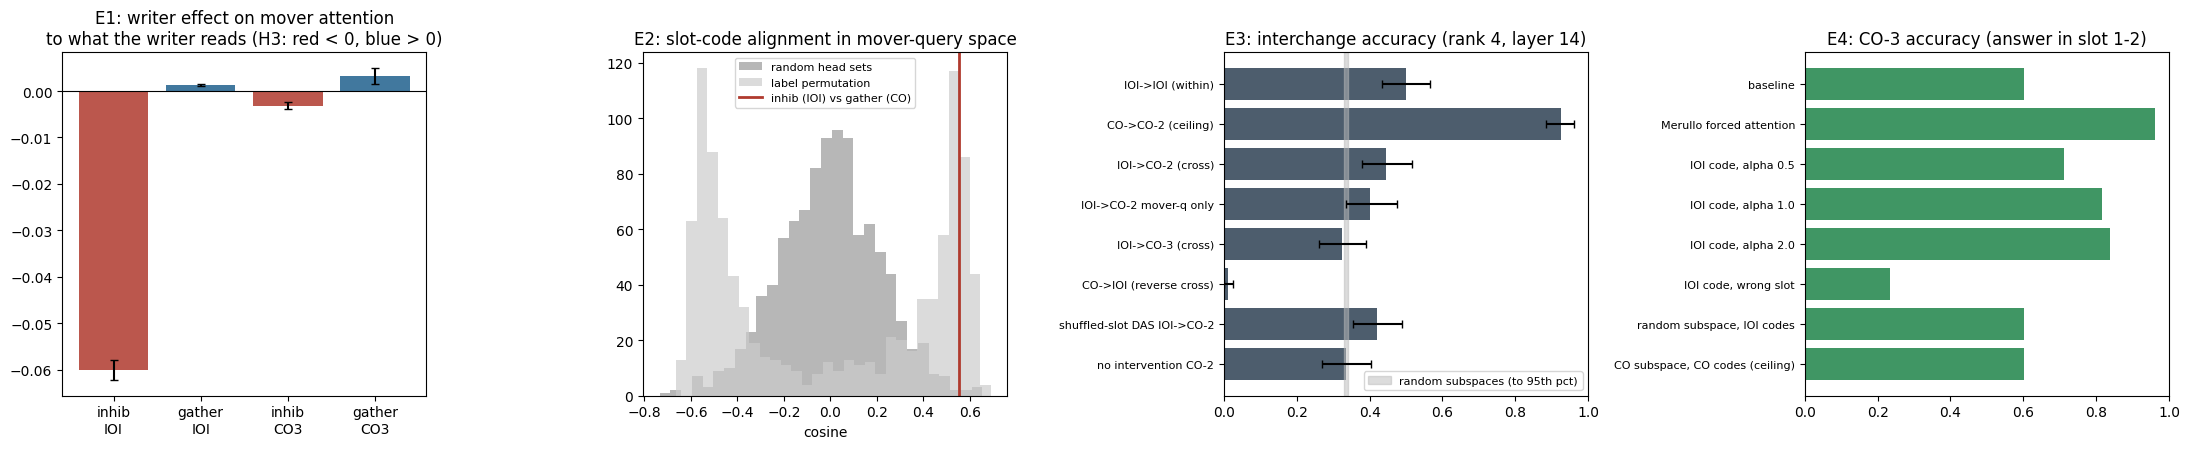

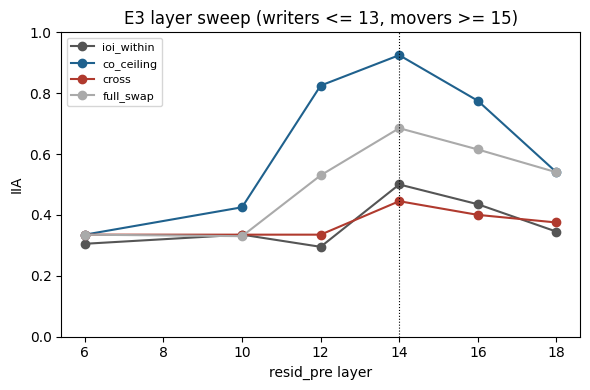

Saved: ['das_subspaces.pt', 'h3_layer_sweep.png', 'h3_summary.png', 'results.json']


In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(22, 4.6))
# E1
labels, means, errs, cols = [], [], [], []
for task in ["ioi", "co3"]:
    for role in ["inhib", "gather"]:
        r_ = E1_GROUP[(task, role)]
        labels.append(f"{role}\n{task.upper()}"); means.append(r_["mean"])
        errs.append([[r_["mean"] - r_["ci"][0]], [r_["ci"][1] - r_["mean"]]])
        cols.append("#b03a2e" if role == "inhib" else "#1f618d")
ax[0].bar(range(4), means, color=cols, alpha=.85)
ax[0].errorbar(range(4), means, yerr=np.hstack(errs), fmt="none", c="k", capsize=3)
ax[0].axhline(0, c="k", lw=.8); ax[0].set_xticks(range(4)); ax[0].set_xticklabels(labels)
ax[0].set_title("E1: writer effect on mover attention\nto what the writer reads (H3: red < 0, blue > 0)")
# E2
ax[1].hist(E2["null_heads"], bins=30, color="#999", alpha=.7, label="random head sets")
ax[1].hist(E2["null_perm"], bins=30, color="#ccc", alpha=.7, label="label permutation")
ax[1].axvline(E2["cos_cross"], c="#b03a2e", lw=2, label="inhib (IOI) vs gather (CO)")
ax[1].set_title("E2: slot-code alignment in mover-query space"); ax[1].set_xlabel("cosine"); ax[1].legend(fontsize=8)
# E3
keys = ["IOI->IOI (within)", "CO->CO-2 (ceiling)", "IOI->CO-2 (cross)", "IOI->CO-2 mover-q only",
        "IOI->CO-3 (cross)", "CO->IOI (reverse cross)", "shuffled-slot DAS IOI->CO-2", "no intervention CO-2"]
vals = [E3["main"][k]["iia"] for k in keys]
lo = [E3["main"][k]["iia"] - E3["main"][k]["ci"][0] for k in keys]
hi = [E3["main"][k]["ci"][1] - E3["main"][k]["iia"] for k in keys]
ax[2].barh(range(len(keys)), vals, xerr=[lo, hi], color="#2e4053", alpha=.85, capsize=3)
ax[2].axvspan(min(rand_iia), E3["rand_p95"], color="#bbb", alpha=.5, label="random subspaces (to 95th pct)")
ax[2].set_yticks(range(len(keys))); ax[2].set_yticklabels(keys, fontsize=8); ax[2].invert_yaxis()
ax[2].set_xlim(0, 1); ax[2].set_title(f"E3: interchange accuracy (rank {PRIMARY_RANK}, layer {DAS_LAYER})"); ax[2].legend(fontsize=8)
# E4
arms = list(E4["co3"].keys())
ax[3].barh(range(len(arms)), [E4["co3"][a]["acc"] for a in arms], color="#1e8449", alpha=.85)
ax[3].set_yticks(range(len(arms))); ax[3].set_yticklabels(arms, fontsize=8); ax[3].invert_yaxis()
ax[3].set_xlim(0, 1); ax[3].set_title("E4: CO-3 accuracy (answer in slot 1-2)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/h3_summary.png", dpi=130); plt.show()

plt.figure(figsize=(6, 4))
Ls = sorted(E3["sweep"])
for k, c in [("ioi_within", "#555"), ("co_ceiling", "#1f618d"), ("cross", "#b03a2e"), ("full_swap", "#aaa")]:
    plt.plot(Ls, [E3["sweep"][L][k] for L in Ls], marker="o", label=k, c=c)
plt.axvline(DAS_LAYER, ls=":", c="k", lw=.8); plt.ylim(0, 1); plt.xlabel("resid_pre layer"); plt.ylabel("IIA")
plt.title("E3 layer sweep (writers <= 13, movers >= 15)"); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/h3_layer_sweep.png", dpi=130); plt.show()


def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (np.floating, np.integer, np.bool_)): return o.item()
    if isinstance(o, torch.Tensor): return o.tolist()
    return o


config = {k: globals()[k] for k in ["MODEL_NAME", "LOADED", "TL_VERSION", "SMOKE", "QUICK", "SEED", "PREPEND_BOS", "INHIB", "GATHER",
                                    "MOVERS", "NEG_MOVER", "DAS_LAYER", "SWEEP_LAYERS", "DAS_RANKS", "DAS_SEEDS",
                                    "DAS_STEPS", "DAS_LR", "DAS_BATCH", "N_RAND_SUBSPACES", "TH"]}
results = dict(config=config, verdict=VERDICT, checks=checks, E0=E0,
               E1={f"{t}/{w[0]}.{w[1]}": {k: v for k, v in r_.items() if k != "effect"} for (t, w), r_ in E1.items()},
               E1_group={f"{t}/{role}": v for (t, role), v in E1_GROUP.items()},
               E2={k: v for k, v in E2.items()},
               E3=dict(primary_rank=PRIMARY_RANK, rho=E3["rho"], rand_mean=E3["rand_mean"], rand_p95=E3["rand_p95"],
                       main={k: {kk: vv for kk, vv in v.items() if kk != "iia_raw"} for k, v in E3["main"].items()},
                       runs={f"{s}/r{r_}/s{sd}": {t: (v["iia"] if isinstance(v, dict) else v) for t, v in d.items()}
                             for (s, r_, sd), d in E3["runs"].items()},
                       sweep=E3["sweep"]),
               E4=E4, dropped={f"{a}: {b}": c for (a, b), c in DROPPED.items()},
               prompts={k: [dict(base=p["base"]["text"], src=p["src"]["text"]) for p in v[:50]] for k, v in PAIRS.items()})
with open(f"{OUT_DIR}/results.json", "w") as fh:
    json.dump(to_jsonable(results), fh, indent=1)
torch.save({f"{s}_r{r_}_s{sd}": Q.cpu() for (s, r_, sd), Q in QS.items()}, f"{OUT_DIR}/das_subspaces.pt")
print("Saved:", sorted(os.listdir(OUT_DIR)))
if SAVE_TO_DRIVE:
    from google.colab import drive
    import shutil
    drive.mount("/content/drive")
    shutil.copytree(OUT_DIR, f"/content/drive/MyDrive/{OUT_DIR}", dirs_exist_ok=True)

## What to settle before the confirmatory run
1. **Head lists.** These are the published Merullo lists. Swap in your Phase 1 step-1 reproduction;
   if 14.14 or 13.3 turn out to matter, add them and re-run E1–E3.
2. **DAS site.** Layer 14 is fixed in advance because it sits between writers and movers. If the sweep
   peaks elsewhere, pre-register that layer for the confirmatory run; don't pick it on the CO numbers.
3. **Rank.** Fix the primary rank from this pilot's IOI-only rule.
4. **Thresholds** in `TH` are proposals. Set them from the pilot's noise (seed spread, CI widths)
   before running fresh prompts.
5. **Slot vs position.** The variable here is "order of mention". If E3 passes, a follow-up should
   separate order from absolute distance (insert filler between candidates) and from binding-ID style
   codes; if E3 fails, check whether IOI and CO slots differ only in distance to the final token.
6. **E1 in CO** depends on the inhibitors reading the test colours at all. Merullo report they mostly
   read the demo answer; if their mass on candidates is below threshold, E1 for inhibitors in CO is
   untestable rather than failed.
7. **Environment.** The code paths were smoke-tested with TransformerLens 2.18.0, torch 2.14 and
   transformers 5.19 on a tiny random model; GPT-2 Medium itself has not been loaded yet. If
   `from_pretrained` fails on a newer `huggingface_hub`, run `%pip install -q "huggingface_hub<1.0"`
   and restart the runtime.